# HW2 conceptual part:

##  **Question 1: The Importance of Adding Bias and Activation Functions to Neural Networks**



###<font color='orange'>**Bias:**</font>

1. **Increasing Model Flexibility**: Bias allows neurons to adjust their output by a constant value, enhancing the neural network's ability to learn complex patterns.
2. **Shifting the Decision Boundary**: Without bias, all output functions of the neural network pass through the origin in a linear fashion. Bias enables neurons to adjust the decision boundary to pass through any desired point, aiding in the classification of complex data.
3. **Offsetting the Line from the Origin**: Bias allows the line (or decision boundary) to move away from the origin, providing additional flexibility in fitting the data.

### <font color='orange'>**Activation Function:**</font>

1. **Adding Non-linearity to the Model**: Activation functions allow the neural network to model non-linear relationships. Without activation functions, a neural network would simply be a linear combination of inputs, even if it has hidden layers.
2. **Preventing Gradient Vanishing and Explosion**: Specific activation functions, such as ReLU (Rectified Linear Unit), help mitigate issues like gradient vanishing and explosion.
3. **Controlling Output Range**: Activation functions often limit the output to a specific range (for example, between 0 and 1 for sigmoid, or between -1 and 1 for hyperbolic tangent), which can aid in numerical stability and improve training speed.
4. **Controlled Behavior**: The activation function should have a controlled range and upper limit, typically being non-linear, as linear behavior usually does not yield correct results.



### <font color='lightblue'>**Conclusion:**</font>
By combining bias and activation functions, neural networks can learn and generalize better, effectively solving more complex problems.

##  **Question 2: Differences Between Adaline and Perceptron Networks Learning Algorithm**



### <font color='orange'>Perceptron Learning</font>

1. **Learning Algorithm**:
   - The perceptron learning algorithm updates weights based on the error between predicted and actual outputs in each iteration.
   - It follows a rule where if the predicted output does not match the actual output, the weights are adjusted.
   - This adjustment continues until the algorithm converges or reaches a maximum number of iterations.
   - It can only classify linearly separable data. If the data is not linearly separable, the perceptron algorithm does not converge.

2. **Hebbian Learning with Repetition**:
   - The perceptron uses a modified version of Hebb's rule for learning. Unlike Hebb’s original rule, which updates weights only once based on input-output correlation, the perceptron rule allows for repeated adjustments.
   - Weights are adjusted iteratively, reinforcing the correct weights over multiple presentations of the data.

3. **Error Handling**:
   - In perceptron learning, the exact magnitude of the error is not considered. As long as there is a misclassification, the weights are updated.
   - The update is binary, meaning it only checks whether the classification is correct or incorrect, not by how much.





### <font color='orange'>Adaline Learning</font>

1. **Learning Algorithm**:
   - Adaline uses the least mean squares (LMS) method for learning.
   - The error is calculated as the difference between the actual and predicted output, and this continuous error is used to update the weights.
   - The weight adjustment formula minimizes the mean squared error between the actual output and the predicted output.
   - Adaline is capable of making more precise adjustments to the weights due to the continuous nature of the error calculation, even though it still cannot handle non-linear data.

2. **Error Handling**:
   - In Adaline learning, the magnitude of the error is directly considered in the weight update process.
   - The update is based on minimizing the continuous error (mean squared error), allowing for more fine-grained adjustments to the weights.



### <font color='lightblue'>Key Differences in Learning</font>

1. **Error Calculation**:
   - The perceptron learning algorithm calculates binary errors (correct or incorrect classification) and updates weights regardless of the error's magnitude.
   - Adaline uses a continuous error measure (mean squared error), which directly influences the weight updates based on the error's magnitude.

2. **Convergence and Data Handling**:
   - The perceptron learning algorithm converges only if the data is linearly separable.
   - Adaline, while also limited to linear separability, provides a smoother convergence path by minimizing the continuous error.

3. **Repetition in Learning**:
   - Perceptron learning involves repeated adjustments based on errors until convergence, allowing it to iteratively refine weights.
   - Adaline also involves iterative updates, but its adjustments are based on minimizing continuous errors rather than binary classification errors.



## **Question 3: Adam Optimizer**







The Adam (Adaptive Moment Estimation) optimizer is a popular algorithm used to train neural networks in deep learning. It was introduced by Diederik P. Kingma and Jimmy Ba in 2014. Adam combines the best features of two other algorithms: AdaGrad and RMSProp.



### Key Features and Advantages

1. **Adaptive Learning Rates**:
   - Adam adjusts the learning rate for each parameter individually, which helps in faster and more efficient training.

2. **Moment Estimation**:
   - Adam uses moving averages of the gradients and the squared gradients to make the training more stable and efficient.



### How Adam Works

1. **Initialization**:
   - Start with initial values for the parameters (weights) and set the first moment (mean of gradients) and second moment (mean of squared gradients) to zero.

2. **Updating Estimates**:
   - For each step during training:
     - Update the first moment (mean of gradients).
     - Update the second moment (mean of squared gradients).

3. **Bias Correction**:
   - Adjust the estimates to correct any bias that might have been introduced during the initial steps.

4. **Parameter Update**:
   - Use the corrected estimates to update the parameters (weights).



### The Formulas

Here are the simplified steps in mathematical terms:

1. **Initialization**:
   - Initialize parameters (weights) randomly.
   - Initialize first moment $m$ and second moment $v$ to zero.

2. **Updating Estimates**:
   - For each step $t$:
     - Update the first moment:  
       $m_t = \beta_1 \cdot m_{t-1} + (1 - \beta_1) \cdot g_t$
     - Update the second moment:  
       $v_t = \beta_2 \cdot v_{t-1} + (1 - \beta_2) \cdot g_t^2$

3. **Bias Correction**:
   - Correct the estimates:
       $\hat{m}_t = \frac{m_t}{1 - \beta_1^t}$
       $\hat{v}_t = \frac{v_t}{1 - \beta_2^t}$

4. **Parameter Update**:
   - Update the parameters (weights):
       $\theta_t = \theta_{t-1} - \alpha \cdot \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}$
     - $\epsilon$ is a small number to prevent division by zero.



### Advantages of Adam

- **Fast Convergence**: It converges quickly, making it suitable for training deep networks.
- **Handles Noisy Data**: It works well with noisy data and sparse gradients.
- **Wide Use**: Adam is used extensively in various machine learning and deep learning applications because of its simplicity and efficiency.



### Disadvantages of Adam

- **Parameter Tuning**: It still requires careful tuning of hyperparameters (like learning rates).
- **Suboptimal Convergence**: Sometimes, it may converge to a suboptimal solution.

The Adam optimizer is a powerful tool for training neural networks, combining the strengths of other optimization techniques to provide a robust and efficient training process.

# HW2 implementation part:

##  **Question 4: Fisher's Iris Dataset**



### Loading the Dataset
In this section, we will load the Fisher's Iris dataset using `sklearn.datasets.load_iris` and convert it to PyTorch tensors.


First, we import the necessary libraries. We need `torch` from PyTorch and `load_iris` from scikit-learn.



In [1]:
import torch
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

Next, we load the Iris dataset. `X` contains the features, and `y` contains the labels.


In [2]:
iris = load_iris()
X, y = iris.data, iris.target

We then convert the data to PyTorch tensors. This conversion allows us to leverage PyTorch's tensor operations and GPU acceleration.


In [3]:
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)

Finally, we display the shapes of the features and labels to verify the data loading process.


In [4]:
print(f"Features shape: {X.shape}")
print(f"Labels shape: {y.shape}")

Features shape: torch.Size([150, 4])
Labels shape: torch.Size([150])


### Splitting the Dataset
Next, we split the dataset into training and testing sets using an 80-20 split.


We import the `train_test_split` function from scikit-learn, which will help us split the dataset.


In [5]:
from sklearn.model_selection import train_test_split

We Split the dataset into training (80%) and testing (20%) sets. We specify `test_size=0.2` to allocate 20% of the data for testing and use `random_state=42` to ensure reproducibility.The choice of `random_state=42` is arbitrary; it could be any integer. Using a random state ensures that the split will be the same every time you run the code, which is important for reproducibility.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Finally, we display the shapes of the training and testing sets to verify the split.


In [7]:
print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")
print(f"Training labels shape: {y_train.shape}")
print(f"Testing labels shape: {y_test.shape}")

Training features shape: torch.Size([120, 4])
Testing features shape: torch.Size([30, 4])
Training labels shape: torch.Size([120])
Testing labels shape: torch.Size([30])


- **Training features shape: `torch.Size([120, 4])`**
  - This indicates that the training features have 120 samples, each with 4 features.
- **Testing features shape: `torch.Size([30, 4])`**
  - This indicates that the testing features have 30 samples, each with 4 features.
- **Training labels shape: `torch.Size([120])`**
  - This indicates that there are 120 labels corresponding to the 120 training samples.
- **Testing labels shape: `torch.Size([30])`**
  - This indicates that there are 30 labels corresponding to the 30 testing samples.

## **Question 5: Adaline Neural Network on Fisher's Iris Dataset**


### Introduction

We aim to implement the Adaline neural network using PyTorch on the Fisher's Iris dataset. The dataset has 5 columns and 150 rows, with 3 classes and 4 features corresponding to different flower species. We will focus on two classes of our choice and visualize the decision boundary during each iteration of the algorithm.

### Importing Libraries

First, we import the necessary libraries including PyTorch, Matplotlib, and Scikit-learn.

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

- `torch` and `torch.nn` are imported for building and training the neural network.
- `matplotlib.pyplot` is used for plotting graphs and visualizing the decision boundary.
- `load_iris` from `sklearn.datasets` is used to load the Iris dataset.
- `train_test_split` from `sklearn.model_selection` is used to split the dataset into training and testing sets.
- `StandardScaler` from `sklearn.preprocessing` is used to standardize the features.
- `os` is used for creating directories to save plots.

### Loading and Preprocessing the Dataset
We load the Iris dataset and select two classes (0 and 1). We then standardize the features for better performance.


In [ ]:
# Loading the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Using only two classes (0 and 1)
X = X[y != 2]
y = y[y != 2]
y = torch.where(torch.tensor(y) == 1, -1, 1).float()

# Standardizing features
scaler = StandardScaler()
X_std = scaler.fit_transform(X)
X_std = torch.tensor(X_std, dtype=torch.float32)

- The Iris dataset is loaded into `X` (features) and `y` (labels).
- We filter out class 2, keeping only classes 0 and 1.
- Labels are converted to -1 and 1 using PyTorch's `torch.where` function.
  - `torch.tensor(y)` converts the NumPy array `y` to a PyTorch tensor.
  - `torch.where(torch.tensor(y) == 1, -1, 1)` replaces 1 with -1 and 0 with 1.
  - `.float()` converts the tensor to a float type.
- Features are standardized using `StandardScaler` to ensure they have a mean of 0 and a standard deviation of 1.
- The standardized features are converted to PyTorch tensors.

### Defining the Adaline Model in PyTorch
We implement the Adaline neural network in PyTorch, defining the model, the training function, and the prediction function.


In [ ]:
class Adaline(nn.Module):
    def __init__(self, input_dim, lr=0.01, threshold=1e-5):
        super(Adaline, self).__init__()
        self.linear = nn.Linear(input_dim, 1)
        self.lr = lr
        self.threshold = threshold
        self.converged = False

    def forward(self, x):
        return self.linear(x)

    def fit(self, X, y, n_iter=2000, plot_interval=50, X_train=None, y_train=None, feature_names=None):
        criterion = nn.MSELoss()
        optimizer = torch.optim.SGD(self.parameters(), lr=self.lr)
        self.errors = []

        for i in range(n_iter):
            outputs = self.forward(X)
            loss = criterion(outputs, y.view(-1, 1))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            self.errors.append(loss.item())

            if len(self.errors) > 1 and abs(self.errors[-2] - self.errors[-1]) < self.threshold:
                self.converged = True
                self.convergence_iter = i
                break

            if i % plot_interval == 0 and X_train is not None and y_train is not None:
                plot_decision_boundary(self, X_train, y_train, f'Decision Boundary at Iteration {i}', feature_names)

        return self

    def predict(self, X):
        with torch.no_grad():
            outputs = self.forward(X)
            return torch.where(outputs >= 0, 1, -1)

- The `Adaline` class inherits from `nn.Module` and defines a simple linear model with one linear layer.
- The `__init__` method initializes the linear layer, learning rate, threshold for convergence, and a flag to check if convergence is reached.
- The `forward` method defines the forward pass of the model, which simply involves applying the linear transformation.
- The `fit` method trains the model using mean squared error loss and stochastic gradient descent optimizer. It iterates over the training data for a specified number of iterations (`n_iter`), computing the loss, performing backpropagation, and updating the weights. The loss at each iteration is stored in `self.errors`. If the change in error between iterations falls below the threshold, training stops early and the iteration number is recorded. The decision boundary is plotted at specified intervals.
- The `predict` method predicts the class labels for given input data by applying the forward pass and using a threshold of 0 to decide between class -1 and 1.

### Plotting the Decision Boundary

We define a function to plot the decision boundary of the trained model, including a convergence message if applicable.


In [ ]:
def plot_decision_boundary(model, X, y, title, feature_names):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = torch.meshgrid(torch.arange(x_min, x_max, 0.01), torch.arange(y_min, y_max, 0.01))
    grid = torch.cat([xx.reshape(-1, 1), yy.reshape(-1, 1)], dim=1)
    predictions = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, predictions, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, marker='o', s=50, edgecolor='k')
    plt.title(title)
    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])

    if model.converged:
        plt.text(x_max - 1, y_min + 0.5, f'Converged at iteration {model.convergence_iter}', fontsize=12, color='red', ha='right')

    plt.show()

- **Function arguments**: Takes the trained model, input features (`X`), labels (`y`), plot title (`title`), and feature names (`feature_names`) as input.
- **Grid creation**: Creates a grid of points covering the feature space.
- **Predictions**: Makes predictions for each point in the grid.
- **Plotting**: Plots the decision boundary using `contourf` to show regions of different predicted classes. Overlays the actual data points using `scatter`.
- **Convergence message**: Displays a convergence message on the plot if the model has converged.

### Training and Visualizing the Decision Boundary

We create combinations of features, train the Adaline model on each combination, and visualize the decision boundary for both training and testing data.

In [ ]:
feature_combinations = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
feature_names = iris.feature_names

for combo in feature_combinations:
    X_train, X_test, y_train, y_test = train_test_split(X_std[:, list(combo)], y, test_size=0.2, random_state=42)

    model = Adaline(input_dim=2, lr=0.01, threshold=1e-5).fit(X_train, y_train, n_iter=2000, plot_interval=50, X_train=X_train, y_train=y_train, feature_names=[feature_names[combo[0]], feature_names[combo[1]]])

    # Plot decision boundary for training data
    plot_decision_boundary(model, X_train, y_train, f'Training Decision Boundary for Features {feature_names[combo[0]]} & {feature_names[combo[1]]}',
                           [feature_names[combo[0]], feature_names[combo[1]]])

    # Plot decision boundary for testing data
    plot_decision_boundary(model, X_test, y_test, f'Testing Decision Boundary for Features {feature_names[combo[0]]} & {feature_names[combo[1]]}',
                           [feature_names[combo[0]], feature_names[combo[1]]])


Output hidden; open in https://colab.research.google.com to view.

- We define combinations of features to visualize how the decision boundary looks with different pairs of features.
- For each combination, the dataset is split into training and testing sets.
- The Adaline model is trained on the training set. Training stops early if the change in error falls below the specified threshold. The decision boundary is plotted at specified intervals.
- The decision boundary is plotted for both training and testing data to visualize how well the model separates the two classes. A convergence message is displayed on the plot if applicable.

### Plotting the Learning Curve
Finally, we plot the learning curve to visualize the sum-squared-error over the epochs.


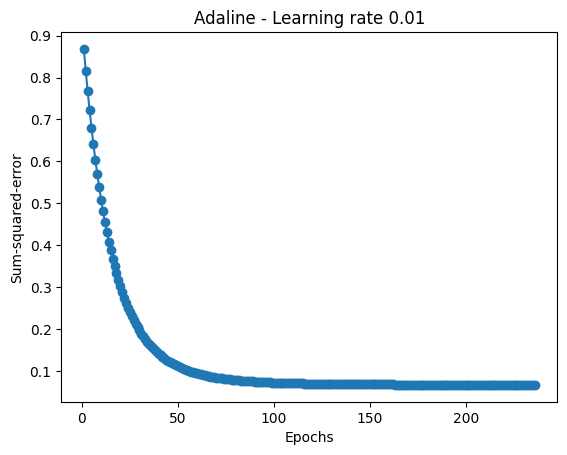

In [ ]:
plt.plot(range(1, len(model.errors) + 1), model.errors, marker='o')
plt.xlabel('Epochs')
plt.ylabel('Sum-squared-error')
plt.title('Adaline - Learning rate 0.01')
plt.show()

The learning curve shows the sum-squared-error over the epochs, providing insight into how the model's error decreases over time.


### Summary

In conclusion, we implemented the Adaline neural network using PyTorch on the Fisher's Iris dataset. We trained the model on two classes of flowers and visualized the decision boundary for both training and testing data during each iteration. The learning curve demonstrates the reduction of error over time, validating the efficiency of our model.

By examining the plots, we can determine if the decision boundary correctly separates the classes. In cases where perfect separation isn't possible, it may indicate that the classes are not linearly separable. This would require a more complex model, such as a nonlinear classifier, to achieve better separation. The stopping criterion based on the change in error ensures that training stops when the model has converged, making the process more efficient.

## **Question 6: Three-Class Classification on Fisher's Iris Dataset**


### Introduction

We aim to solve a three-class classification problem on the Fisher's Iris dataset using two algorithms: Perceptron and Adaline. We will train and evaluate these models on the dataset.

### Importing Libraries

First, we import the necessary libraries including PyTorch, Matplotlib, and Scikit-learn.

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import numpy as np

- **torch and torch.nn**: These are imported for building and training the neural networks using PyTorch.
- **matplotlib.pyplot**: This is used for plotting graphs and visualizing results.
- **load_iris**: This function from `sklearn.datasets` is used to load the Iris dataset.
- **train_test_split**: This function from `sklearn.model_selection` is used to split the dataset into training and testing sets.
- **StandardScaler**: This function from `sklearn.preprocessing` is used to standardize the features.
- **accuracy_score**: This function from `sklearn.metrics` is used to evaluate the accuracy of the models.
- **confusion_matrix and ConfusionMatrixDisplay**: These functions from `sklearn.metrics` are used to compute and display the confusion matrix for the classification results.

### Loading and Preprocessing the Dataset

We load the Iris dataset and standardize the features.

In [ ]:
iris = load_iris()
X = iris.data
y = iris.target

scaler = StandardScaler()
X_std = scaler.fit_transform(X)
X_std = torch.tensor(X_std, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)

- **Load the dataset**: The Iris dataset is loaded into `X` (features) and `y` (labels).
- **Standardize features**: Features are standardized using `StandardScaler` to ensure they have a mean of 0 and a standard deviation of 1.
- **Convert to tensors**: The standardized features and labels are converted to PyTorch tensors.

### Defining the Perceptron Model in PyTorch
We implement the Perceptron neural network in PyTorch, defining the model, the training function, and the prediction function.


In [ ]:
class Perceptron(nn.Module):
    def __init__(self, input_dim, output_dim, lr=0.01, threshold=1e-5):
        super(Perceptron, self).__init__()
        self.linear = nn.Linear(input_dim, output_dim)
        self.lr = lr
        self.threshold = threshold
        self.converged = False

    def forward(self, x):
        return self.linear(x)

    def fit(self, X, y, n_iter=200):
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.SGD(self.parameters(), lr=self.lr)
        self.errors = []

        for epoch in range(n_iter):
            outputs = self.forward(X)
            loss = criterion(outputs, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            self.errors.append(loss.item())

            with torch.no_grad():
                predictions = torch.max(self.forward(X), 1)[1]
                misclassified = (predictions != y).sum().item()
                if misclassified == 0:
                    self.converged = True
                    self.convergence_epoch = epoch
                    break

        return self

    def predict(self, X):
        with torch.no_grad():
            outputs = self.forward(X)
            _, predicted = torch.max(outputs, 1)
            return predicted

**Perceptron Class:**

1. **Initialization (`__init__` method)**:
   - **Parameters**:
     - `input_dim`: The number of input features.
     - `output_dim`: The number of output classes.
     - `lr`: Learning rate for the gradient descent optimizer.
     - `threshold`: Convergence threshold to stop training if the weights do not change significantly (not used here but kept for consistency).
   - **Attributes**:
     - `self.linear`: A linear layer with `input_dim` inputs and `output_dim` outputs.
     - `self.lr`: The learning rate used for the optimizer.
     - `self.threshold`: The convergence threshold (though not directly used here).
     - `self.converged`: A flag to indicate if the model has converged.
     - `self.convergence_epoch`: The epoch at which the model converged.

2. **Forward Pass (`forward` method)**:
   - **Parameters**:
     - `x`: The input data tensor.
   - **Returns**:
     - The output of the linear transformation applied to the input data.

3. **Training (`fit` method)**:
   - **Parameters**:
     - `X`: The training data tensor.
     - `y`: The training labels tensor.
     - `n_iter`: The number of iterations (epochs) to train the model.
   - **Attributes**:
     - `criterion`: The loss function used for training, which is CrossEntropyLoss for classification.
     - `optimizer`: The optimizer used for updating the model's weights, which is Stochastic Gradient Descent (SGD).
     - `self.errors`: A list to store the loss values for each iteration.
   - **Training Loop**:
     - For each iteration:
       - Compute the model's output using the `forward` method.
       - Calculate the loss using the `criterion`.
       - Perform backpropagation by calling `loss.backward()`.
       - Update the model's weights using `optimizer.step()`.
       - Append the current loss value to `self.errors`.
       - **Convergence Check**:
         - After updating the weights, check the number of misclassifications.
         - If there are no misclassifications, set the `self.converged` flag and record the `self.convergence_epoch`, then break the loop.

4. **Prediction (`predict` method)**:
   - **Parameters**:
     - `X`: The input data tensor.
   - **Returns**:
     - The predicted class labels for the input data.
   - This method computes the model's output for the input data and returns the class with the highest score for each input sample.



### Training and Evaluating the Perceptron Model
We split the dataset into training and testing sets, train the Perceptron model, and evaluate its performance.


Perceptron Model - Cross-Validation Testing Accuracies: [1.0, 0.9333333333333333, 0.9333333333333333, 0.9, 0.9666666666666667]
Perceptron Model - Average Testing Accuracy: 0.95


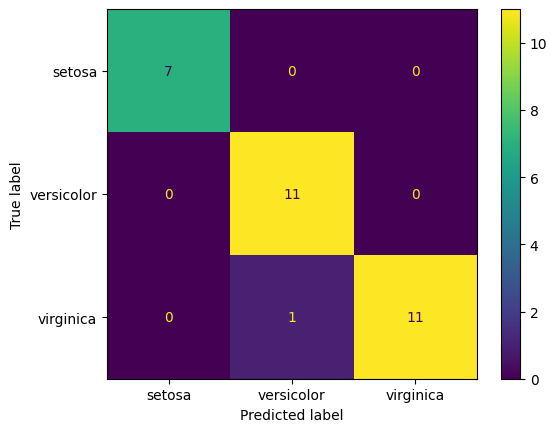

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
perceptron_accuracies = []

for train_index, test_index in kf.split(X_std):
    X_train, X_test = X_std[train_index], X_std[test_index]
    y_train, y_test = y[train_index], y[test_index]

    perceptron_model = Perceptron(input_dim=4, output_dim=3, lr=0.1)
    perceptron_model.fit(X_train, y_train, n_iter=500)

    y_pred_test = perceptron_model.predict(X_test)
    test_accuracy = accuracy_score(y_test, y_pred_test)
    perceptron_accuracies.append(test_accuracy)

print(f'Perceptron Model - Cross-Validation Testing Accuracies: {perceptron_accuracies}')
print(f'Perceptron Model - Average Testing Accuracy: {np.mean(perceptron_accuracies):.2f}')

cm = confusion_matrix(y_test, y_pred_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
disp.plot()
plt.show()


1. **Train-test split**: We split the dataset into training and testing sets using k-fold cross-validation.
   - `kf = KFold(n_splits=5, shuffle=True, random_state=42)`
   - The `KFold` function from Scikit-learn is used to split the standardized feature matrix `X_std` and the target vector `y` into 5 folds for cross-validation.

2. **Model training**: We initialize and train the Perceptron model on the training set for each fold.
   - `perceptron_model.fit(X_train, y_train, n_iter=3000)`
   - The `fit` method of the `Perceptron` class is called with the training data and labels. The model is trained for up to 500 iterations. If the model converges (i.e., all training samples are correctly classified), training stops early.

3. **Prediction and evaluation**: We predict class labels on the testing sets for each fold, and evaluate the model's accuracy using `accuracy_score`.
   - The `predict` method of the `Perceptron` class is used to generate predictions for the testing data. The `accuracy_score` function calculates the ratio of correctly predicted samples to the total number of samples, providing the testing accuracy for each fold.

4. **Accuracy metrics**:
   - **Cross-Validation Testing Accuracies**: The testing accuracies for each fold are printed.
   - **Average Testing Accuracy**: The average testing accuracy across all folds is calculated and printed.

5. **Convergence Check**:
   - The `fit` method includes a convergence check where the

 training process stops early if all training samples are correctly classified in an iteration.


### Observations on Perceptron Model

- **High Training Accuracy**: Indicates that the model has effectively learned the training data.
- **High Testing Accuracy**: Indicates that the model generalizes well to new, unseen data.

### Defining the Adaline Model in PyTorch
The Adaline algorithm, unlike the Perceptron, uses the actual error value for weight updates. The error reduction is based on the delta rule.


In [ ]:
class Adaline(nn.Module):
    def __init__(self, input_dim, output_dim, lr=0.01, threshold=1e-5):
        super(Adaline, self).__init__()
        self.linear = nn.Linear(input_dim, output_dim)
        self.lr = lr
        self.threshold = threshold
        self.converged = False

    def forward(self, x):
        return self.linear(x)

    def fit(self, X, y, n_iter=200):
        criterion = nn.MSELoss()
        optimizer = torch.optim.SGD(self.parameters(), lr=self.lr)
        self.errors = []

        y_onehot = torch.zeros(y.size(0), 3)
        y_onehot[torch.arange(y.size(0)), y] = 1

        for i in range(n_iter):
            outputs = self.forward(X)
            loss = criterion(outputs, y_onehot)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            self.errors.append(loss.item())

            if len(self.errors) > 1 and abs(self.errors[-2] - self.errors[-1]) < self.threshold:
                self.converged = True
                self.convergence_epoch = i
                break

        return self

    def predict(self, X):
        with torch.no_grad():
            outputs = self.forward(X)
            _, predicted = torch.max(outputs, 1)
            return predicted


**Adaline Class:**

1. **Initialization (`__init__` method)**:
   - **Parameters**:
     - `input_dim`: The number of input features.
     - `output_dim`: The number of output classes.
     - `lr`: Learning rate for the gradient descent optimizer.
     - `threshold`: Convergence threshold to stop training if the change in error is below this value.
   - **Attributes**:
     - `self.linear`: A linear layer with `input_dim` inputs and `output_dim` outputs.
     - `self.lr`: The learning rate used for the optimizer.
     - `self.threshold`: The convergence threshold for early stopping.
     - `self.converged`: A flag to indicate if the model has converged.
     - `self.convergence_epoch`: The epoch at which the model converged.

2. **Forward Pass (`forward` method)**:
   - **Parameters**:
     - `x`: The input data tensor.
   - **Returns**:
     - The output of the linear transformation applied to the input data.

3. **Training (`fit` method)**:
   - **Parameters**:
     - `X`: The training data tensor.
     - `y`: The training labels tensor.
     - `n_iter`: The number of iterations (epochs) to train the model.
   - **Attributes**:
     - `criterion`: The loss function used for training, which is Mean Squared Error (MSE) for Adaline.
     - `optimizer`: The optimizer used for updating the model's weights, which is Stochastic Gradient Descent (SGD).
     - `self.errors`: A list to store the loss values for each iteration.
     - `y_onehot`: The one-hot encoded labels for multi-class classification.
   - **Training Loop**:
     - For each iteration:
       - Compute the model's output using the `forward` method.
       - Calculate the loss using the `criterion`.
       - Perform backpropagation by calling `loss.backward()`.
       - Update the model's weights using `optimizer.step()`.
       - Append the current loss value to `self.errors`.
       - **Convergence Check**:
         - Check for convergence by comparing the change in error with the threshold. If the change is below the threshold, set the `self.converged` flag and record the convergence iteration.

4. **Prediction (`predict` method)**:
   - **Parameters**:
     - `X`: The input data tensor.
   - **Returns**:
     - The predicted class labels for the input data.
   - This method computes the model's output for the input data and returns the class with the highest score for each input sample.



### Training and Evaluating the Adaline Model
We train the Adaline model and evaluate its performance.


Adaline Model - Cross-Validation Testing Accuracies: [0.8333333333333334, 0.8, 0.8666666666666667, 0.8, 0.8333333333333334]
Adaline Model - Average Testing Accuracy: 0.83


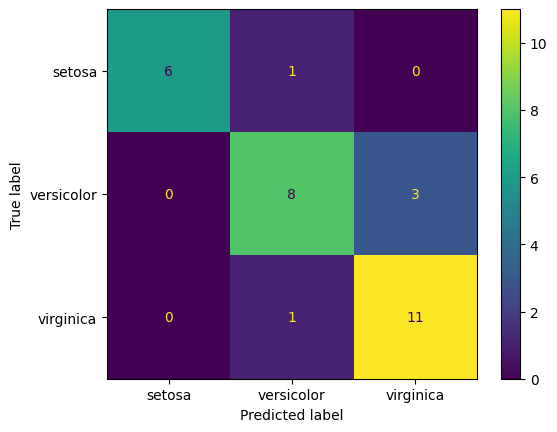

In [ ]:
adaline_accuracies = []

for train_index, test_index in kf.split(X_std):
    X_train, X_test = X_std[train_index], X_std[test_index]
    y_train, y_test = y[train_index], y[test_index]

    adaline_model = Adaline(input_dim=4, output_dim=3, lr=0.01, threshold=1e-5)
    adaline_model.fit(X_train, y_train, n_iter=500)

    y_pred_test = adaline_model.predict(X_test)
    test_accuracy = accuracy_score(y_test, y_pred_test)
    adaline_accuracies.append(test_accuracy)

print(f'Adaline Model - Cross-Validation Testing Accuracies: {adaline_accuracies}')
print(f'Adaline Model - Average Testing Accuracy: {np.mean(adaline_accuracies):.2f}')

cm = confusion_matrix(y_test, y_pred_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
disp.plot()
plt.show()


- **Train-test split**: Split the dataset into training and testing sets using k-fold cross-validation.
  - The `KFold` function from Scikit-learn splits the standardized feature matrix `X_std` and the target vector `y` into 5 folds for cross-validation.

- **Model training**: Initialize and train the Adaline model on the training set for each fold.
  - `adaline_model.fit(X_train, y_train, n_iter=2000)`
  - The `fit` method of the `Adaline` class is called with the training data and labels. The model is trained for up to 2000 iterations. If the model converges (i.e., the change in error is below the threshold), training stops early.

- **Prediction and evaluation**: Predict class labels on the testing sets for each fold, and evaluate the model's accuracy using `accuracy_score`.
  - The `predict` method of the `Adaline` class is used to generate predictions for the testing data. The `accuracy_score` function calculates the ratio of correctly predicted samples to the total number of samples, providing the testing accuracy for each fold.

- **Convergence Check**:
  - The `fit` method includes a convergence check where the training process stops early if the change in loss between iterations is below the threshold.


### Summary

Finally, we implemented and compared two neural network models, Perceptron and Adaline, for three-class classification on the Fisher's Iris dataset. Both models were trained on the dataset, and their performance was evaluated using accuracy metrics and confusion matrix plots. By analyzing the results, we can understand the strengths and weaknesses of each model for multi-class classification problems.


## **Question 7: Designing and Implementing a Neural Network for XOR Classification**


### Introduction
In this question, we will design and implement a neural network to classify the XOR problem. The XOR problem is a classic example used to demonstrate the capabilities of neural networks to solve non-linearly separable problems.


### Importing necessary libraries
In this step, we import all the necessary libraries for our implementation, including PyTorch, numpy, and matplotlib for data handling and visualization.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

- **torch and torch.nn**: Used for building and training neural networks.
- **torch.optim**: Provides optimization algorithms such as Adam.
- **numpy**: Used for numerical operations and handling arrays.
- **matplotlib.pyplot**: Used for plotting graphs and visualizing results.

### Generating and Preparing Data
We generate the XOR data, which consists of four points, and convert this data into PyTorch tensors.

In [ ]:
x = np.array([[0,0], [0,1], [1,0], [1,1]], dtype=np.float32)
y = np.array([[0], [1], [1], [0]], dtype=np.float32)

x_tensor = torch.tensor(x, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)

- **x**: The input features for the XOR problem.
- **y**: The corresponding labels for the XOR problem.
- **x_tensor and y_tensor**: The input features and labels converted to PyTorch tensors.

### Defining the Neural Network
We define a neural network with two hidden layers. Each hidden layer uses the ReLU activation function, and the output layer uses a sigmoid activation function for binary classification.


In [ ]:
class XORNN(nn.Module):
    def __init__(self):
        super(XORNN, self).__init__()
        self.hidden1 = nn.Linear(2, 4)
        self.hidden2 = nn.Linear(4, 4)
        self.output = nn.Linear(4, 1)
        self.activation = nn.ReLU()

    def forward(self, x):
        x = self.activation(self.hidden1(x))
        x = self.activation(self.hidden2(x))
        x = torch.sigmoid(self.output(x))
        return x
# Initialize the model
model = XORNN()

- **__init__**: Initializes the layers of the neural network.
  - **self.hidden1**: First hidden layer with 2 input features and 4 neurons.
  - **self.hidden2**: Second hidden layer with 4 neurons.
  - **self.output**: Output layer with 4 input features and 1 neuron.
  - **self.activation**: ReLU activation function.
- **forward**: Defines the forward pass through the network.
  - Applies the ReLU activation function to the hidden layers and the Sigmoid activation function to the output layer.

### Specifying the Loss Function and Optimizer
We use the binary cross-entropy loss function (`BCELoss`) suitable for binary classification tasks and the Adam optimizer to train the model.

In [ ]:
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

- **criterion**: Binary cross-entropy loss function.
- **optimizer**: Adam optimizer used to update the model parameters.

### Training the Model
We train the model for 20,000 epochs. During each epoch, we perform a forward pass, compute the loss, perform a backward pass, and update the weights. We also print the loss every 1,000 epochs to monitor training progress.

In [ ]:
num_epochs = 20000

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(x_tensor)
    loss = criterion(outputs, y_tensor)
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 1000 == 0:
        print(f'Epoch [{epoch + 1}/{num_epochs}], Loss: {loss.item():.4f}')

Epoch [1000/20000], Loss: 0.0027
Epoch [2000/20000], Loss: 0.0007
Epoch [3000/20000], Loss: 0.0003
Epoch [4000/20000], Loss: 0.0002
Epoch [5000/20000], Loss: 0.0001
Epoch [6000/20000], Loss: 0.0000
Epoch [7000/20000], Loss: 0.0000
Epoch [8000/20000], Loss: 0.0000
Epoch [9000/20000], Loss: 0.0000
Epoch [10000/20000], Loss: 0.0000
Epoch [11000/20000], Loss: 0.0000
Epoch [12000/20000], Loss: 0.0000
Epoch [13000/20000], Loss: 0.0000
Epoch [14000/20000], Loss: 0.0000
Epoch [15000/20000], Loss: 0.0000
Epoch [16000/20000], Loss: 0.0000
Epoch [17000/20000], Loss: 0.0000
Epoch [18000/20000], Loss: 0.0000
Epoch [19000/20000], Loss: 0.0000
Epoch [20000/20000], Loss: 0.0000


- **num_epochs**: Total number of epochs for training.
- **model.train()**: Sets the model to training mode.
- **optimizer.zero_grad()**: Clears the previous gradients.
- **outputs**: The predicted outputs from the model.
- **loss**: The computed binary cross-entropy loss.
- **loss.backward()**: Computes the gradients.
- **optimizer.step()**: Updates the model parameters.


### Evaluating the Model
We evaluate the model by making predictions on the XOR data and comparing them to the expected results. We also print the predictions and expected values for verification.

In [ ]:
model.eval()
with torch.no_grad():
    predicted = model(x_tensor).numpy()
    predicted = np.round(predicted)  # Round predictions to 0 or 1

# Print predictions and expected values
print("Test data:")
print(x)
print("Predictions:")
print(predicted)
print("Expected:")
print(y)

Test data:
[[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]
Predictions:
[[0.]
 [1.]
 [1.]
 [0.]]
Expected:
[[0.]
 [1.]
 [1.]
 [0.]]


- **model.eval()**: Sets the model to evaluation mode.
- **torch.no_grad()**: Disables gradient calculation for evaluation.
- **predicted**: The predicted outputs from the model.
- **np.round(predicted)**: Rounds the predictions to 0 or 1.

### Plotting the Results
Finally, we visualize the actual data points and the model's predictions. Correctly predicted points are marked distinctly for easy verification.


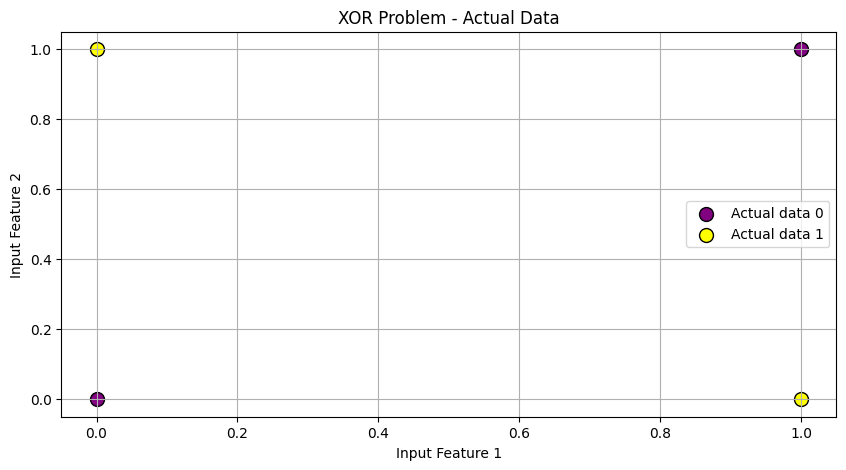

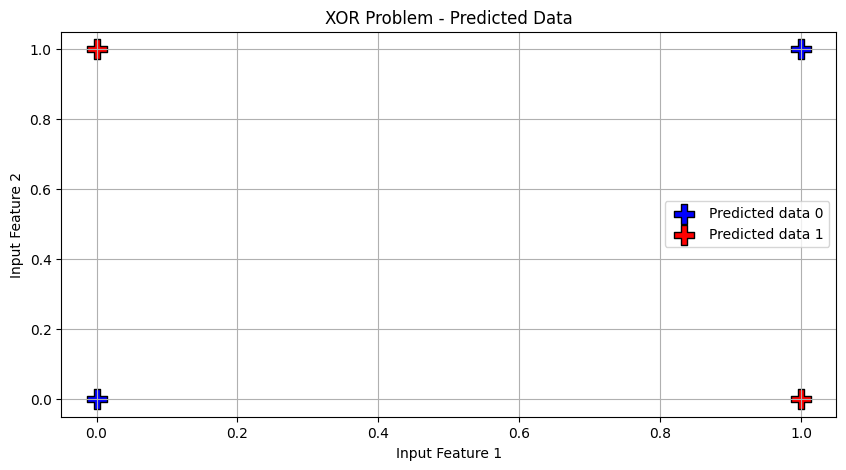

In [ ]:
# Plotting the actual data
plt.figure(figsize=(10, 5))
# Plotting actual data points with distinct colors and adding them to the legend
plt.scatter(x[y[:, 0] == 0, 0], x[y[:, 0] == 0, 1], c='purple', label='Actual data 0', edgecolors='k', s=100, marker='o')
plt.scatter(x[y[:, 0] == 1, 0], x[y[:, 0] == 1, 1], c='yellow', label='Actual data 1', edgecolors='k', s=100, marker='o')
plt.legend(loc='best')
plt.title("XOR Problem - Actual Data")
plt.xlabel("Input Feature 1")
plt.ylabel("Input Feature 2")
plt.grid(True)
plt.show()

# Plotting the predicted data
plt.figure(figsize=(10, 5))
for i, point in enumerate(x):
    if predicted[i] == 1:
        plt.scatter(point[0], point[1], c='red', marker='P', s=200, edgecolors='k', label='Predicted data 1' if i == 0 else "")
    else:
        plt.scatter(point[0], point[1], c='blue', marker='P', s=200, edgecolors='k', label='Predicted data 0' if i == 0 else "")

# Adding legend entries manually
plt.scatter([], [], c='red', marker='P', s=200, edgecolors='k', label='Predicted data 1')

plt.legend(loc='best')
plt.title("XOR Problem - Predicted Data")
plt.xlabel("Input Feature 1")
plt.ylabel("Input Feature 2")
plt.grid(True)
plt.show()

- **Plotting the actual data**: Visualizes the actual data points with distinct colors for each class.
- **Plotting the predicted data**: Visualizes the model's predictions with distinct markers for each predicted class.

### Summary
In this exercise, we successfully designed and implemented a neural network to classify the XOR problem using PyTorch. We defined a neural network with two hidden layers using ReLU activation functions and an output layer using a sigmoid activation function. The model was trained using the Adam optimizer and the binary cross-entropy loss function. After training the model for 20,000 epochs, we evaluated its performance and visualized the actual data points and the model's predictions.